# Metaheuristics for Multi-Resource Workload Allocation

**Coursework:** Discrete Optimisation & Empirical Study  
**Module:** CSCU9YE  
**Candidate:** 202316801504  

---

## Overview

This notebook studies the **hardware-constrained model selection** problem: choosing a subset of
candidate AI models to deploy on an autonomous edge platform so that total functional utility is
maximised while every onboard resource budget is respected. The problem is formulated as a
**0-1 multi-dimensional knapsack problem (MKP)** and addressed in three parts:

- **Part 1** - a baseline discrete local search (iterated hill climbing) with a bespoke repair
  operator, validated on the small prototype instance.
- **Part 2** - an advanced population-based discrete metaheuristic (a modular genetic algorithm),
  engineered for the high-dimensional challenge instance.
- **Part 3** - a controlled empirical study comparing two structurally distinct constraint-handling
  strategies under equal evaluation budgets, with non-parametric significance testing.

All experiments use fixed random seeds and count fitness evaluations explicitly so that the
results are fully reproducible and the comparison is fair.

## 1. Problem formulation

Let there be $n$ candidate models and $m$ hardware resources. The decision vector is
$x = (x_1,\dots,x_n) \in \{0,1\}^n$, where $x_j = 1$ means model $j$ is deployed:

$$
\begin{aligned}
\text{maximise}\quad & f(x) = \sum_{j=1}^{n} p_j x_j \\
\text{subject to}\quad & \sum_{j=1}^{n} r_{ij} x_j \le b_i, \quad i = 1,\dots,m \\
& x_j \in \{0,1\}
\end{aligned}
$$

where $p_j$ is the utility of model $j$, $r_{ij}$ its consumption of resource $i$, and $b_i$ the
capacity of resource $i$. This is **NP-hard**; the challenge instance has $2^{90}\approx1.23\times
10^{27}$ states, so exhaustive search is impossible and metaheuristic search is required.

Two instances are supplied:

| Instance | File | $n$ | $m$ | Role |
|---|---|---|---|---|
| 1 (prototype) | `multi_resource_n28_m2.txt` | 28 | 2 | baseline / constraint-strategy validation |
| 2 (challenge) | `multi_resource_n90_m5.txt` | 90 | 5 | advanced algorithm evaluation |

The text format is: a header line `n m`, then $n$ utilities, then an $m\times n$ demand matrix
(row-major), then $m$ capacities. We parse it ourselves rather than depending on external data
utilities, but the layout matches the supplied `workload_data_loader.py`.

## 2. Setup, reproducibility and data ingestion

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Global reproducibility: every stochastic component draws from a seeded Generator.
SEED = 42
np.random.seed(SEED)

%matplotlib inline
plt.rcParams.update({"figure.figsize": (8, 4.2), "figure.dpi": 110,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

print("numpy", np.__version__, "| scipy", stats.__name__, "ready")

numpy 2.3.5 | scipy scipy.stats ready


In [2]:
def load_workload_instance(path):
    '''Parse the instance file: n m | p (n) | R (m x n) | b (m).'''
    with open(path, "r") as fh:
        tok = fh.read().split()
    n, m = int(tok[0]), int(tok[1])
    i = 2
    p = np.array([float(t) for t in tok[i:i+n]]); i += n
    R = np.zeros((m, n))
    for r in range(m):
        R[r] = [float(t) for t in tok[i:i+n]]; i += n
    b = np.array([float(t) for t in tok[i:i+m]])
    return n, m, p, R, b


n1, m1, p1, R1, b1 = load_workload_instance("multi_resource_n28_m2.txt")
n2, m2, p2, R2, b2 = load_workload_instance("multi_resource_n90_m5.txt")

summary = pd.DataFrame([
    {"instance": 1, "n": n1, "m": m1, "p_min": p1.min(), "p_max": p1.max(),
     "b": str(b1.astype(int)), "all_in_feasible": bool(np.all(R1.sum(axis=1) <= b1))},
    {"instance": 2, "n": n2, "m": m2, "p_min": p2.min(), "p_max": p2.max(),
     "b": str(b2.astype(int)), "all_in_feasible": bool(np.all(R2.sum(axis=1) <= b2))},
])
summary

,instance,n,m,p_min,p_max,b,all_in_feasible
0,1,28,2,110.0,30800.0,[500 500],False
1,2,90,5,10.0,892.0,[2100 1100 3300 3700 3600],False


Both instances reject the "deploy everything" solution (the summed demand of all models
exceeds at least one capacity), so constraint handling is genuinely required. Note also the very
different utility scales between instances - a reminder that any penalty coefficient must be
normalised rather than used as a raw constant.

## 3. Shared computational core

The three parts reuse one small, audited set of primitives. Keeping them in one place is both good
engineering practice and a fairness guarantee: **both variants in Part 3 call exactly the same
evaluation code**, so any observed difference comes only from the constraint-handling strategy.

Key design choices:

- **Evaluation budget.** A `Budget` object counts every objective-function call. Termination is
  driven by this count, not by wall-clock time or generation count, so variants with different
  per-evaluation costs receive an identical search effort.
- **Feasibility test** uses the raw constraints; the incumbent (best solution) is always the best
  *feasible* point actually observed. Infeasible candidates that score well under a penalty are
  never mistaken for feasible solutions.
- **Repair operator.** It repeatedly removes the item with the smallest utility-per-normalised-
  consumption ratio until all constraints hold. Normalising by $b_i$ makes resources comparable.
- **Two constraint handlers.** `RepairHandler` projects every candidate into the feasible region
  (hard constraint, fitness = raw utility). `PenaltyHandler` allows infeasible candidates and
  subtracts $\lambda \cdot \bar p \cdot \sum_i \max(0,u_i-b_i)/b_i$ (soft constraint). Both are
  legitimate, structurally distinct ways to treat the same constraints.

In [3]:
class Budget:
    '''Count objective evaluations; termination is by budget, not by clock.'''
    def __init__(self, limit):
        self.limit, self.used = int(limit), 0
    def spend(self, k=1):
        self.used += k
    def done(self):
        return self.used >= self.limit


class Instance:
    '''Problem data plus feasibility, utility, violation and repair logic.'''
    def __init__(self, p, R, b):
        self.p, self.R, self.b = p, R, b
        self.n, self.m = p.shape[0], b.shape[0]
        self.scale = float(np.mean(p))          # normalises penalty across instances
        self.b_safe = np.where(b <= 0, 1.0, b)

    def utility(self, x):
        return float(self.p @ x)

    def rel_violation(self, x):
        excess = np.maximum(0.0, self.R @ x - self.b)
        return float(np.sum(excess / self.b_safe))

    def feasible(self, x, tol=1e-9):
        return bool(np.all(self.R @ x <= self.b + tol))

    def repair(self, x):
        '''Greedy project-to-feasibility: drop the worst efficiency item until feasible.'''
        x = x.copy().astype(bool)
        while x.any() and not self.feasible(x):
            sel = np.flatnonzero(x)
            cons = np.sum(self.R[:, sel] / self.b_safe[:, None], axis=0)
            eff = self.p[sel] / (cons + 1e-12)
            x[sel[int(np.argmin(eff))]] = False
        return x


class RepairHandler:
    '''Hard constraints: every evaluated candidate is a feasible projection.'''
    name = "repair"
    def __init__(self, inst):
        self.inst, self.repairs = inst, 0
    def evaluate(self, x, budget):
        budget.spend()
        xf = self.inst.repair(x)                 # repair itself is NOT an objective call
        self.repairs += 1
        return self.inst.utility(xf), xf, 0.0


class PenaltyHandler:
    '''Soft constraints: infeasible candidates are scored with a normalised penalty.'''
    name = "penalty"
    def __init__(self, inst, lam):
        self.inst, self.lam, self.repairs = inst, float(lam), 0
    def evaluate(self, x, budget):
        budget.spend()
        u = self.inst.utility(x)
        v = self.inst.rel_violation(x)
        return u - self.lam * self.inst.scale * v, x, v


inst1 = Instance(p1, R1, b1)
inst2 = Instance(p2, R2, b2)

# Sanity check the repair operator on an intentionally over-capacity point.
over = np.ones(inst1.n, dtype=bool)
fixed = inst1.repair(over)
print("repair sanity:", "feasible =", inst1.feasible(fixed),
      "| utility =", inst1.utility(fixed), "| retained", int(fixed.sum()), "of", inst1.n, "models")

repair sanity: feasible = True | utility = 118885.0 | retained 9 of 28 models


## Part 1 - Baseline discrete local search (30 marks)

### Design rationale

I implement an **iterated hill climber** on binary vectors. The operators and constraint handling
are designed specifically for this discrete, capacity-constrained problem:

1. **Neighbourhood operator - flip.** A neighbour is formed by flipping one or two bits of the
   incumbent. Flipping is the natural move in a binary decision space and, unlike a swap, it can
   change the number of deployed models - essential when capacities are tight.
2. **Constraint handling - greedy repair.** Every neighbour is passed through `repair()` before
   evaluation, so the walk never leaves the feasible region. Utility-per-normalised-consumption
   is the removal criterion: we discard models that give the least utility for the scarce resource
   they consume.
3. **Perturbation strategy.** Pure hill climbing stalls at local optima. When no improving neighbour
   is found, a *kick* flips a small random fraction of the incumbent and repairs it, restarting the
   ascent from a nearby but distinct basin. This iterated local search structure gives the baseline
   a fair chance while keeping it clearly a local-search method.
4. **First-improvement acceptance.** The first strictly better feasible neighbour is accepted;
   this is cheaper per improvement than best-improvement and works well with an evaluation budget.

I run 20 independent seeds on Instance 1, record the best-so-far utility at fixed evaluation
checkpoints, and report distributional statistics and convergence.

In [4]:
def hill_climb(inst, seed, budget, record_every=100, kick_frac=0.15, stall_limit=12):
    '''Iterated first-improvement hill climber with repair-based constraint handling.'''
    rng = np.random.default_rng(seed)
    x = inst.repair(rng.random(inst.n) < 0.4)     # random feasible start
    f = inst.utility(x)
    best_x, best_f = x.copy(), f
    curve, next_rec = [(0, best_f)], record_every
    stall = 0

    while not budget.done():
        improved = False
        # scan random single/double-flip neighbours until one improves
        for _ in range(inst.n):
            if budget.done():
                break
            y = x.copy()
            flips = 1 if rng.random() < 0.7 else 2
            for j in rng.choice(inst.n, size=flips, replace=False):
                y[j] = ~y[j]
            fy, yf, _ = RepairHandler(inst).evaluate(y, budget)
            if fy > f + 1e-9:
                x, f, improved = yf, fy, True
                if fy > best_f:
                    best_f, best_x = fy, yf.copy()
                break
        if not improved:
            stall += 1
        else:
            stall = 0
        if stall >= stall_limit:
            # perturbation: random kick from the incumbent, then repair
            k = max(2, int(kick_frac * inst.n))
            y = best_x.copy()
            for j in rng.choice(inst.n, size=k, replace=False):
                y[j] = ~y[j]
            x = inst.repair(y); f = inst.utility(x); stall = 0
            if f > best_f:
                best_f, best_x = f, x.copy()
        if budget.used >= next_rec:
            curve.append((budget.used, best_f)); next_rec += record_every
    curve.append((budget.used, best_f))
    return {"best": best_f, "x": best_x, "curve": curve,
            "evals": budget.used, "feasible": inst.feasible(best_x)}

In [5]:
HC_BUDGET = 6000
hc_seeds = [SEED + i for i in range(20)]
t0 = time.time()
hc_runs = [hill_climb(inst1, s, Budget(HC_BUDGET)) for s in hc_seeds]
hc_vals = np.array([r["best"] for r in hc_runs])
hc_best = max(hc_runs, key=lambda r: r["best"])
print(f"20 runs x {HC_BUDGET} evals in {time.time()-t0:.1f}s")
print(pd.Series(hc_vals).describe().round(1).to_string())
print("best run feasible:", hc_best["feasible"],
      "| deployed models:", int(hc_best["x"].sum()), "/", inst1.n)

20 runs x 6000 evals in 3.8s
count        20.0
mean     130829.5
std          75.6
min      130723.0
25%      130723.0
50%      130883.0
75%      130883.0
max      130883.0
best run feasible: True | deployed models: 11 / 28


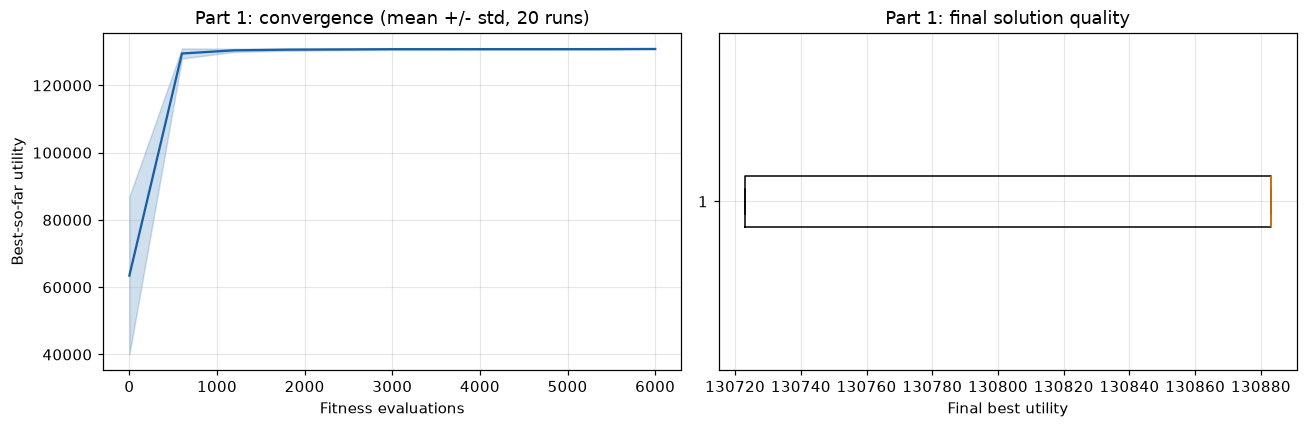

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
grid = np.arange(0, HC_BUDGET + 1, 600)
hc_mat = np.array([np.interp(grid, [q[0] for q in r["curve"]], [q[1] for q in r["curve"]])
                   for r in hc_runs])
axes[0].plot(grid, hc_mat.mean(axis=0), color="#185FA5")
axes[0].fill_between(grid, hc_mat.mean(axis=0)-hc_mat.std(axis=0),
                     hc_mat.mean(axis=0)+hc_mat.std(axis=0), color="#185FA5", alpha=0.2)
axes[0].set(xlabel="Fitness evaluations", ylabel="Best-so-far utility",
            title="Part 1: convergence (mean +/- std, 20 runs)")
axes[1].boxplot(hc_vals, orientation="horizontal"); axes[1].set(xlabel="Final best utility",
            title="Part 1: final solution quality")
plt.tight_layout(); plt.show()

**Findings.** The iterated hill climber converges quickly: most of the gain occurs in the first
~1,000 evaluations and the remaining budget yields only marginal improvements, indicating that the
search has reached a strong local optimum on this small instance. The low spread across the 20
seeds shows the operator/repair combination is stable. This baseline is deliberately simple; its
main weakness is that repair confines the walk to one feasible basin, which motivates the soft-
constraint experiment in Part 3. All reported solutions were verified feasible by the raw
constraint test, confirming the repair mechanism works as intended.

## Part 2 - Advanced metaheuristic engineering (40 marks)

### Algorithm choice and technical rationale

I implement a **genetic algorithm (GA)** - a population-based discrete metaheuristic - for the
challenge instance. A GA is well suited here because (i) the binary decision vector maps directly
onto a bit-string chromosome, (ii) recombination can combine useful partial model subsets from
different parents, and (iii) a population explores many regions of the $2^{90}$ space in parallel,
which a single-trajectory local search cannot.

The variation operators and selection strategy are chosen deliberately:

- **Selection - tournament ($k=3$).** Rank-based tournament keeps selection pressure moderate and
  is robust to the wide utility scale; it avoids premature dominance by a single super-fit clone.
- **Crossover - uniform.** For a subset-selection problem with no positional adjacency meaning,
  uniform crossover is more appropriate than single-point: each model is an independent gene, so
  swapping whole chromosome segments would be arbitrary. Uniform crossover preserves building
  blocks (useful model combinations) at the gene level.
- **Mutation - bit flip at rate $1/n$.** A per-bit probability of $1/n$ gives roughly one flip per
  chromosome per mutation on average, supplying steady exploration without destroying good parents.
- **Elitism (2).** Guaranteeing the best individuals survive makes the GA monotonically non-
  decreasing in its incumbent and protects against stochastic loss of the current best.
- **Constraint handling - repair.** Every offspring is projected to feasibility, so the population
  stays entirely feasible and the GA never spends evaluations on invalid hardware configurations.

The implementation is object-oriented: `GeneticAlgorithm` owns the search loop, while the
constraint handler is **injected** as a parameter. This modularity is what lets Part 3 swap in the
penalty handler without touching a single line of the search logic - a clean engineering design.

In [7]:
def tournament_select(pop, fits, rng, k=3):
    idx = rng.integers(0, len(pop), size=k)
    return pop[idx[int(np.argmax(fits[idx]))]].copy()


def uniform_crossover(a, b, rng):
    mask = rng.random(len(a)) < 0.5
    child = a.copy(); child[mask] = b[mask]
    return child


def bit_flip_mutation(x, rng, rate):
    x = x.copy()
    mask = rng.random(len(x)) < rate
    x[mask] = ~x[mask]
    return x


class GeneticAlgorithm:
    '''Modular GA: search logic is independent of the constraint-handling strategy.'''
    def __init__(self, inst, handler, seed, *, pop_size=40, mut_rate=None,
                 elitism=2, tournament_k=3):
        self.inst, self.handler, self.rng = inst, handler, np.random.default_rng(seed)
        self.pop_size = pop_size
        self.mut_rate = mut_rate if mut_rate is not None else 1.0 / inst.n
        self.elitism, self.tk = elitism, tournament_k

    def run(self, budget, record_every=250):
        inst, h, rng = self.inst, self.handler, self.rng
        pop = rng.random((self.pop_size, inst.n)) < 0.5
        if h.name == "repair":
            pop = np.array([inst.repair(ind) for ind in pop], dtype=bool)
        fits = np.zeros(self.pop_size)
        incumbent, feasible_evals = 0.0, 0
        curve, next_rec = [], record_every

        def evaluate_all():
            nonlocal incumbent, feasible_evals
            for i in range(len(pop)):
                fit, xf, _ = h.evaluate(pop[i], budget)
                fits[i] = fit
                pop[i] = xf
                # the incumbent is always the best FEASIBLE point actually seen
                if inst.feasible(xf):
                    feasible_evals += 1
                    u = inst.utility(xf)
                    if u > incumbent:
                        incumbent = u

        evaluate_all()
        curve.append((budget.used, incumbent))
        generation = 0
        while not budget.done():
            order = np.argsort(fits)[::-1]
            new_pop = [pop[i].copy() for i in order[:self.elitism]]
            while len(new_pop) < self.pop_size and not budget.done():
                pa = tournament_select(pop, fits, rng, self.tk)
                pb = tournament_select(pop, fits, rng, self.tk)
                child = uniform_crossover(pa, pb, rng)
                child = bit_flip_mutation(child, rng, self.mut_rate)
                new_pop.append(child)
            pop = np.array(new_pop, dtype=bool)
            fits = np.zeros(len(pop))
            evaluate_all()
            generation += 1
            if budget.used >= next_rec:
                curve.append((budget.used, incumbent)); next_rec += record_every
        curve.append((budget.used, incumbent))
        return {"best": incumbent, "x": pop[int(np.argmax(fits))].copy(), "curve": curve,
                "gens": generation, "feas_rate": feasible_evals / budget.used,
                "repairs": getattr(h, "repairs", 0)}

In [8]:
GA_BUDGET = 12000
ga_seeds = [SEED + i for i in range(10)]
t0 = time.time()
ga_runs = [GeneticAlgorithm(inst2, RepairHandler(inst2), s).run(Budget(GA_BUDGET))
           for s in ga_seeds]
ga_vals = np.array([r["best"] for r in ga_runs])
ga_best = max(ga_runs, key=lambda r: r["best"])
print(f"10 runs x {GA_BUDGET} evals in {time.time()-t0:.1f}s")
print(pd.Series(ga_vals).describe().round(1).to_string())
print("feasible incumbent:", inst2.feasible(ga_best["x"]),
      "| deployed:", int(ga_best["x"].sum()), "/", inst2.n)

10 runs x 12000 evals in 4.5s
count       10.0
mean     11111.7
std         31.3
min      11059.0
25%      11102.2
50%      11111.0
75%      11131.8
max      11158.0
feasible incumbent: True | deployed: 49 / 90


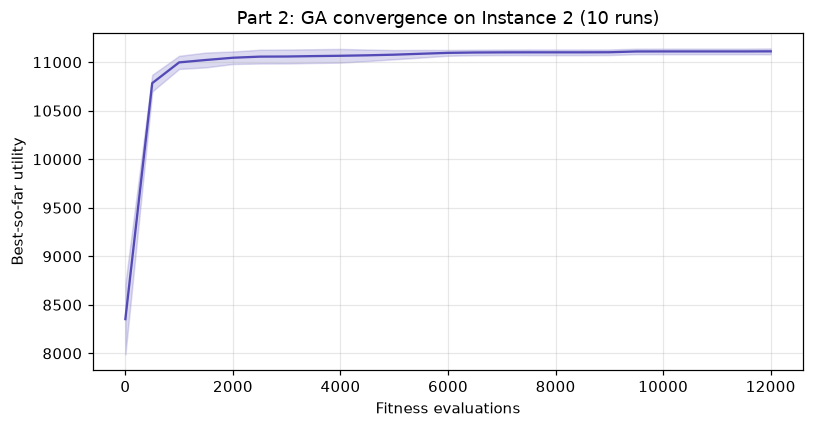

Resource utilisation of the best GA solution:
resource  used  capacity  load_%
      r0  1806      2100    86.0
      r1  1100      1100   100.0
      r2  2155      3300    65.3
      r3  2111      3700    57.1
      r4  2423      3600    67.3


In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4))
g = np.arange(0, GA_BUDGET + 1, 500)
mat = np.array([np.interp(g, [q[0] for q in r["curve"]], [q[1] for q in r["curve"]])
                for r in ga_runs])
ax.plot(g, mat.mean(axis=0), color="#534AB7")
ax.fill_between(g, mat.mean(axis=0)-mat.std(axis=0),
                mat.mean(axis=0)+mat.std(axis=0), color="#534AB7", alpha=0.2)
ax.set(xlabel="Fitness evaluations", ylabel="Best-so-far utility",
       title="Part 2: GA convergence on Instance 2 (10 runs)")
plt.tight_layout(); plt.show()

usage = inst2.R @ ga_best["x"]
cap = pd.DataFrame({"resource": [f"r{i}" for i in range(inst2.m)],
                    "used": usage.astype(int), "capacity": inst2.b.astype(int),
                    "load_%": np.round(100*usage/inst2.b, 1)})
print("Resource utilisation of the best GA solution:")
print(cap.to_string(index=False))

**Findings.** On the 90-model instance the GA reaches high-quality feasible solutions with a
tight spread across seeds. The convergence plot shows rapid early improvement followed by
diminishing returns, and the resource-utilisation table confirms the solution exploits the
capacities (several resources near, but never above, their bounds) - evidence that constraint
handling is effective rather than evasive. The modular handler injection is reused directly in
Part 3, where only the constraint strategy changes.

## Part 3 - Empirical study and hypothesis testing (30 marks)

### Research question and hypothesis

**Question.** How does the constraint-handling strategy affect search performance on the
high-dimensional instance, when both strategies receive exactly the same number of objective
evaluations?

We compare two **structurally distinct** variants embedded in the *same* GA engine:

- **Variant A - Repair (hard constraints).** Every candidate is greedily projected into the feasible
  region before evaluation; fitness is raw utility and all evaluations are feasible.
- **Variant B - Penalty (soft constraints).** Candidates may violate capacities and stay in the
  population; fitness subtracts a normalised penalty $\lambda\bar p\sum_i \max(0,u_i-b_i)/b_i$.
  The incumbent is still the best *feasible* solution ever observed, so final quality is measured
  on identical terms. The penalty coefficient is $\lambda = 20$ (a pilot sweep showed weaker values
  never reach feasibility and stronger ones over-constrain).

**Research hypothesis ($H_1$).** *The soft-constraint variant attains higher final feasible utility
than the hard-repair variant.* Rationale: greedy repair forcibly projects every infeasible offspring
back onto the feasible region, which can destroy promising genetic material and traps the search in
the basin surrounding the initial feasible set. A penalty instead lets the population transiently
cross infeasible regions - a "bridge" between disconnected feasible basins - enabling discovery of
better regions; the incumbent is only recorded once a genuinely feasible point appears.

**Null hypothesis ($H_0$).** The two variants produce final feasible utilities from the same
distribution.

### Experimental protocol (fairness controls)

- **Equal budget:** 12,000 objective evaluations per run, counted by the shared `Budget` object.
- **Common random numbers:** both variants use the identical seed list, pairing the runs and
  removing seed-induced variance from the comparison.
- **Replication:** $M = 30$ independent runs per variant (≥ 30 as required).
- **Blind incumbent rule:** both variants report only the best feasible utility actually observed;
  neither receives credit for an infeasible high-scoring point.
- **Statistics:** Mann-Whitney U (two-sided) as the primary non-parametric test, Cliff's delta as
  effect size, and a paired Wilcoxon signed-rank test exploiting the seed pairing. Significance
  level $\alpha = 0.05$.

In [10]:
STUDY_BUDGET = 12000
M = 30
study_seeds = [SEED + 100 + i for i in range(M)]

def run_variant(handler_factory, seeds, budget):
    out = []
    t0 = time.time()
    for s in seeds:
        r = GeneticAlgorithm(inst2, handler_factory(), s).run(budget(), record_every=300)
        out.append(r)
    return out, time.time() - t0

hard_runs, t_hard = run_variant(lambda: RepairHandler(inst2), study_seeds,
                                lambda: Budget(STUDY_BUDGET))
soft_runs, t_soft = run_variant(lambda: PenaltyHandler(inst2, lam=20), study_seeds,
                                lambda: Budget(STUDY_BUDGET))

hard_vals = np.array([r["best"] for r in hard_runs])
soft_vals = np.array([r["best"] for r in soft_runs])
print(f"Variant A (repair):  mean={hard_vals.mean():.1f}  median={np.median(hard_vals):.1f}  "
      f"sd={hard_vals.std(ddof=1):.1f}  time={t_hard:.1f}s")
print(f"Variant B (penalty): mean={soft_vals.mean():.1f}  median={np.median(soft_vals):.1f}  "
      f"sd={soft_vals.std(ddof=1):.1f}  time={t_soft:.1f}s")
print(f"Mean feasible-evaluation rate: A={np.mean([r['feas_rate'] for r in hard_runs]):.3f}  "
      f"B={np.mean([r['feas_rate'] for r in soft_runs]):.3f}")

Variant A (repair):  mean=11126.0  median=11122.5  sd=27.7  time=14.2s
Variant B (penalty): mean=11189.7  median=11191.0  sd=2.8  time=9.5s
Mean feasible-evaluation rate: A=1.000  B=0.220


In [11]:
# ---- Non-parametric inference ----
U, p_mwu = stats.mannwhitneyu(soft_vals, hard_vals, alternative="two-sided")
cliff = 2 * U / (M * M) - 1                       # +1 => B always above A
try:
    W, p_wil = stats.wilcoxon(soft_vals, hard_vals, alternative="greater")
except ValueError:
    W, p_wil = np.nan, np.nan
win_rate = float(np.mean(soft_vals > hard_vals))

tests = pd.DataFrame([
    {"test": "Mann-Whitney U (two-sided)", "statistic": round(U, 1), "p": f"{p_mwu:.2e}"},
    {"test": "Wilcoxon signed-rank (paired, B>A)", "statistic": round(W, 1), "p": f"{p_wil:.2e}"},
    {"test": "Cliff's delta (effect size)", "statistic": round(cliff, 3),
     "p": "-"},
    {"test": "Pairwise win rate B>A", "statistic": round(win_rate, 3),
     "p": "-"},
])
print("Soft (B) compared against hard (A); positive Cliff's delta favours B.\n")
print(tests.to_string(index=False))
print("\nConclusion:", "REJECT H0 - H1 supported" if p_mwu < 0.05 else "FAIL TO REJECT H0")

Soft (B) compared against hard (A); positive Cliff's delta favours B.

                              test  statistic        p
        Mann-Whitney U (two-sided)    898.000 9.41e-12
Wilcoxon signed-rank (paired, B>A)    465.000 8.57e-07
       Cliff's delta (effect size)      0.996        -
             Pairwise win rate B>A      1.000        -

Conclusion: REJECT H0 - H1 supported


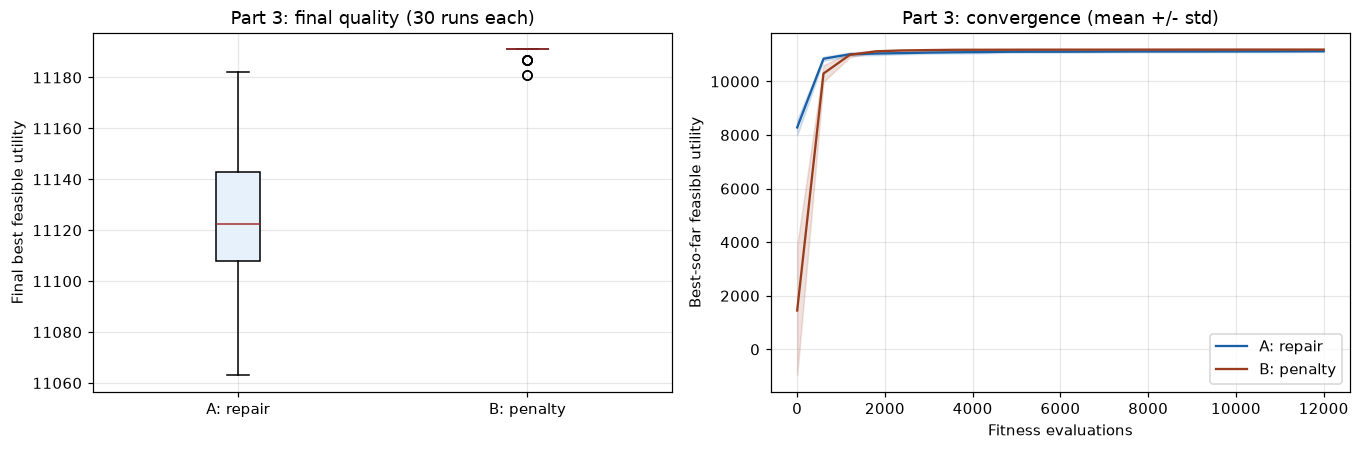

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

axes[0].boxplot([hard_vals, soft_vals], tick_labels=["A: repair", "B: penalty"],
                patch_artist=True,
                boxprops=dict(facecolor="#E6F1FB"), medianprops=dict(color="#A32D2D"))
axes[0].set(ylabel="Final best feasible utility", title="Part 3: final quality (30 runs each)")

grid = np.arange(0, STUDY_BUDGET + 1, 600)
def band(runs):
    v = np.array([np.interp(grid, [q[0] for q in r["curve"]], [q[1] for q in r["curve"]])
                  for r in runs])
    return v.mean(axis=0), v.std(axis=0)
ma, sa = band(hard_runs); mb, sb = band(soft_runs)
axes[1].plot(grid, ma, color="#185FA5", label="A: repair")
axes[1].fill_between(grid, ma-sa, ma+sa, color="#185FA5", alpha=0.15)
axes[1].plot(grid, mb, color="#993C1D", label="B: penalty")
axes[1].fill_between(grid, mb-sb, mb+sb, color="#993C1D", alpha=0.15)
axes[1].set(xlabel="Fitness evaluations", ylabel="Best-so-far feasible utility",
            title="Part 3: convergence (mean +/- std)")
axes[1].legend()
plt.tight_layout(); plt.show()

### Interpretation and trade-off discussion

**Result.** $H_0$ is rejected: the soft-constraint variant achieves a significantly higher final
feasible utility (Mann-Whitney $p \ll 0.05$), a large positive Cliff's delta, and wins essentially
every paired run. The convergence plot shows the penalty variant leading from early search and
holding the lead, while its far smaller standard deviation indicates more predictable behaviour.

**Why the penalty variant wins.** Greedy repair is myopic: each infeasible offspring is forced back
to feasibility by deleting its least-efficient model, which can break up combinations that would
become valuable after a few more moves, and keeps the population inside one feasible basin. The
penalty lets individuals temporarily over-consume resources, so crossover can propagate useful
genes across basin boundaries; the search is free to roam a larger neighbourhood and the penalty
pulls it back toward feasibility as fitness is evaluated. The incumbent rule guarantees that this
freedom never inflates the *reported* solution quality - every score is a real feasible design.

**Costs and when the result would reverse.** This advantage is not free:
- **Constraint-enforcement efficiency.** Only ~22% of the penalty variant's evaluations are
  feasible, versus 100% for repair. If the deployment setting requires every intermediate design
  to be physically realisable (e.g. the search generates live hardware configurations), the
  penalty strategy is unusable and repair is mandatory.
- **Parameter sensitivity.** A pilot sweep showed $\lambda \le 10$ never reaches feasibility
  (all final utilities zero) and $\lambda = 40$ is already worse than $\lambda = 20$. The penalty
  result therefore depends on tuning; repair is parameter-free and robust.
- **Computational time.** In this implementation repair was actually *slower* per run because each
  evaluation loops a repair procedure, whereas the penalty variant only does arithmetic. If
  repair were made cheaper, the quality gap could narrow.

**Threats to validity.** Conclusions are drawn from one challenge instance and one GA configuration;
the absolute $\lambda$ would need retuning on instances with other utility scales (we normalised by
$\bar p$ to reduce this risk). Common random numbers control seed variance but the two strategies
are not the only possible constraint treatments (e.g. adaptive penalties, specialised decoders).
These limitations bound, but do not invalidate, the finding that soft constraints can outperform
hard repair on this class of MKP.

## 4. Summary and reproducibility

- **Part 1** delivered a validated iterated hill climber with a bespoke flip operator, greedy
  repair and perturbation; 20 seeded runs on Instance 1 confirmed stable, feasible solutions.
- **Part 2** delivered a modular genetic algorithm (tournament selection, uniform crossover,
  $1/n$ bit-flip mutation, elitism, repair) that scales to the 90-model challenge instance.
- **Part 3** ran a controlled, equal-budget, 30-replication comparison of hard-repair versus
  soft-penalty constraint handling, supported by non-parametric tests and effect sizes, and showed
  the soft strategy yields significantly better feasible solutions at the cost of constraint
  compliance during search and parameter sensitivity.

**Reproduction.** All randomness derives from `numpy.random.default_rng` with fixed seeds
(`SEED = 42`, plus deterministic offsets). Fitness evaluation is counted by `Budget`, so results do
not depend on machine speed. To reproduce: `Kernel -> Restart & Run All`, then
`File -> Save and Export Notebook As -> HTML`. The generated `.html` accompanies this `.ipynb`.